# Huy Model: Nhận diện chuỗi chữ số viết tay

**CNN Encoder + LSTM Decoder**: ảnh xám 28×224 vào, dãy số (tối đa 8 chữ số) ra.

Ý tưởng:
- Mỗi nhãn được viết thành **8 ô**, mỗi ô là 1 chữ số (0-9), ô thừa điền `10` (PAD). Ví dụ `101651 → [1,0,1,6,5,1,10,10]`.
- **Encoder (CNN)**: trích đặc trưng ảnh và thu chiều ngang về **8 bước**. Ảnh được ghép từ 8 ô rộng 28px, chữ số căn trái, nên mỗi bước ứng với 1 ô chữ số.
- **Decoder (LSTM)**: đi qua 8 bước từ trái sang phải, mỗi bước dự đoán 1 ô (11 lớp: 0-9 và PAD).
- Ghép các chữ số dự đoán thành 1 con số để tính R², NSE, MAE, RMSE.

> Notebook chạy end-to-end: tự tải dữ liệu từ Kaggle nếu chưa có, không gọi file `.py` nào khác trong dự án.

In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from keras import layers, models

## 1. Tải và đọc dữ liệu

In [2]:
DATA_DIR = '../datasets'
if not os.path.exists(f'{DATA_DIR}/images_gray.npy'):
    kagglehub.dataset_download('daitoo/mnist-multi-digit-cache-gray-datasets', output_dir=DATA_DIR)
print(os.listdir(DATA_DIR))

100%|██████████| 57.8M/57.8M [00:08<00:00, 7.26MB/s]


Extracting files...
['.complete', 'images_gray.npy', 'labels.csv']


In [3]:
images = np.load(f'{DATA_DIR}/images_gray.npy')    # (60000, 28, 224, 1), uint8
labels = pd.read_csv(f'{DATA_DIR}/labels.csv', dtype=str)['label'].values   # đọc dạng chuỗi để giữ số 0 ở đầu
print('Ảnh:', images.shape, images.dtype, '| Nhãn:', labels.shape)

Ảnh:

 (60000, 28, 224, 1) uint8 | Nhãn: (60000,)


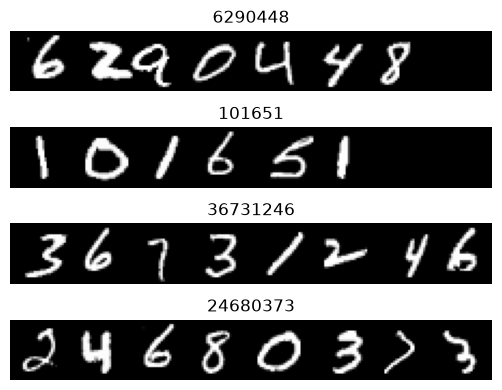

In [4]:
plt.figure(figsize=(10, 4))
for i in range(4):
    plt.subplot(4, 1, i + 1)
    plt.imshow(images[i, :, :, 0], cmap='gray')
    plt.title(labels[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

## 2. Mã hóa nhãn thành 8 ô

In [5]:
MAX_LEN = 8   # tối đa 8 chữ số
PAD = 10      # ô trống

def encode(label):
    digits = [int(c) for c in label]
    return digits + [PAD] * (MAX_LEN - len(digits))

def decode(seq):
    s = ''.join(str(t) for t in seq if t != PAD)
    return int(s) if s else 0

y = np.array([encode(s) for s in labels])
print(labels[0], '->', y[0])

6290448 -> [ 6  2  9  0  4  4  8 10]


## 3. Chia Train / Val / Test (70 / 15 / 15)

Dùng `random_state=42` giống Base_Model để kết quả so sánh được với các bạn trong nhóm.

In [6]:
X_train, X_tmp, y_train, y_tmp = train_test_split(images, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42)
print('Train:', X_train.shape, '| Val:', X_val.shape, '| Test:', X_test.shape)

Train: (42000, 28, 224, 1) | Val: (9000, 28, 224, 1) | Test: (9000, 28, 224, 1)


## 4. Xây dựng mô hình

In [7]:
inp = layers.Input(shape=(28, 224, 1))
x = layers.Rescaling(1 / 255)(inp)                 # đưa pixel về [0, 1]

# Encoder: CNN
x = layers.Conv2D(32, 3, padding='same', activation='relu')(x)
x = layers.MaxPooling2D(2)(x)                      # 14 x 112
x = layers.Conv2D(64, 3, padding='same', activation='relu')(x)
x = layers.MaxPooling2D(2)(x)                      # 7 x 56
x = layers.Conv2D(128, 3, padding='same', activation='relu')(x)
x = layers.MaxPooling2D(7)(x)                      # 1 x 8  -> 8 ô chữ số
x = layers.Reshape((MAX_LEN, 128))(x)              # chuỗi 8 bước, mỗi bước 128 đặc trưng

# Decoder: LSTM sinh 8 chữ số
x = layers.LSTM(128, return_sequences=True)(x)
out = layers.Dense(11, activation='softmax')(x)    # 0-9 và PAD

model = models.Model(inp, out)
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 224, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 28, 224, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 224, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 112, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 112, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 56, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 56, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 8, 128)         │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8, 11)          │         1,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,675 (881.54 KB)

 Trainable params: 225,675 (881.54 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Huấn luyện

In [8]:
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=10, batch_size=128)

Epoch 1/10


329/329 ━━━━━━━━━━━━━━━━━━━━ 74s 218ms/step - accuracy: 0.8573 - loss: 0.4949 - val_accuracy: 0.9709 - val_loss: 0.1075


Epoch 2/10


329/329 ━━━━━━━━━━━━━━━━━━━━ 74s 226ms/step - accuracy: 0.9803 - loss: 0.0687 - val_accuracy: 0.9848 - val_loss: 0.0524


Epoch 3/10


329/329 ━━━━━━━━━━━━━━━━━━━━ 71s 216ms/step - accuracy: 0.9875 - loss: 0.0428 - val_accuracy: 0.9874 - val_loss: 0.0423


... (11 outputs left out)

Epoch 9/10


329/329 ━━━━━━━━━━━━━━━━━━━━ 71s 216ms/step - accuracy: 0.9964 - loss: 0.0119 - val_accuracy: 0.9947 - val_loss: 0.0177


Epoch 10/10


329/329 ━━━━━━━━━━━━━━━━━━━━ 74s 224ms/step - accuracy: 0.9971 - loss: 0.0101 - val_accuracy: 0.9950 - val_loss: 0.0159


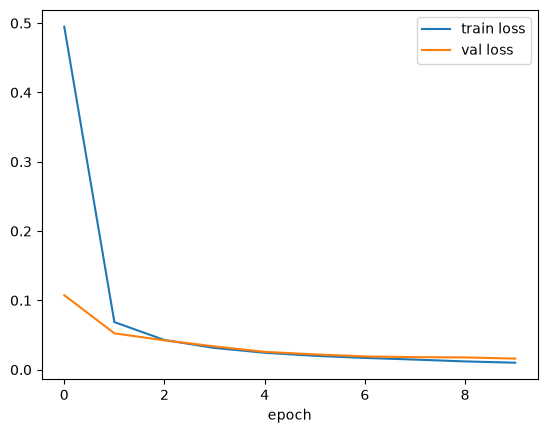

In [9]:
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.xlabel('epoch')
plt.legend()
plt.show()

## 6. Đánh giá trên tập Test

In [10]:
pred = model.predict(X_test, batch_size=256).argmax(axis=-1)    # (N, 8)
y_pred = np.array([decode(s) for s in pred], dtype=float)
y_true = np.array([decode(s) for s in y_test], dtype=float)

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred)
nse = 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)
acc = np.mean(y_true == y_pred)    # tỉ lệ đoán đúng toàn bộ dãy số

print(f'R2: {r2:.4f} | NSE: {nse:.4f} | MAE: {mae:.2f} | RMSE: {rmse:.2f} | Đúng cả dãy: {acc:.2%}')

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step


36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 125ms/step


R2: 0.9958 | NSE: 0.9958 | MAE: 50047.04 | RMSE: 1255009.83 | Đúng cả dãy: 95.81%


In [11]:
for i in range(10):
    print(f'Thật: {int(y_true[i]):>8} | Dự đoán: {int(y_pred[i]):>8}', '' if y_true[i] == y_pred[i] else '  <-- sai')

Thật:  1567788 | Dự đoán:  1567788 
Thật: 58215592 | Dự đoán: 58215592 
Thật:   841128 | Dự đoán:   841128 
Thật: 78916525 | Dự đoán: 78916525 
Thật:  5554378 | Dự đoán:  5554378 
Thật: 26088614 | Dự đoán: 26088614 
Thật:    33259 | Dự đoán:    33259 
Thật:      252 | Dự đoán:      252 
Thật: 23079743 | Dự đoán: 23079743 
Thật:     5284 | Dự đoán:     5284 
